In [2]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [5]:
df = pd.read_csv('decision_tree_project/decision_tree_dataset.csv')
df.describe()
df.head()

0      Drug B
1      Drug D
2      Drug C
3      Drug B
4      Drug D
        ...  
195    Drug A
196    Drug E
197    Drug C
198    Drug E
199    Drug B
Name: Drug, Length: 200, dtype: str

In [6]:
x = df[['Age', 'Gender', 'Cholesterol', 'BloodSugar']].values
y = df['Drug']

0      Drug B
1      Drug D
2      Drug C
3      Drug B
4      Drug D
        ...  
195    Drug A
196    Drug E
197    Drug C
198    Drug E
199    Drug B
Name: Drug, Length: 200, dtype: str

Use LableEncoding to turn the nondigit values to digits such as 0, 1

In [59]:
Gender_le = preprocessing.LabelEncoder()
Gender_le.fit(['Male', 'Female'])
x[:,1] = Gender_le.transform(x[:,1])

Cholesterol_le = preprocessing.LabelEncoder()
Cholesterol_le.fit(['Normal', 'High'])
x[:,2] = Cholesterol_le.transform(x[:,2])

BloodSugar_le = preprocessing.LabelEncoder()
BloodSugar_le.fit(['Normal', 'High', 'Low'])
x[:,3] = BloodSugar_le.transform(x[:,3])


In [60]:
x_trainset, x_testset, y_trainset, y_testset = train_test_split(x, y, test_size = 0.3, random_state=3)

Buliding the model:

In [61]:
drugtree = DecisionTreeClassifier(criterion='entropy', max_depth = 4)

In [62]:
drugtree.fit(x_trainset, y_trainset)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

Prediction:

In [63]:
predtree = drugtree.predict(x_testset)

In [64]:
print("DecisionTrees's accuracy: ", metrics.accuracy_score(y_testset, predtree))

DecisionTrees's accuracy:  0.8333333333333334


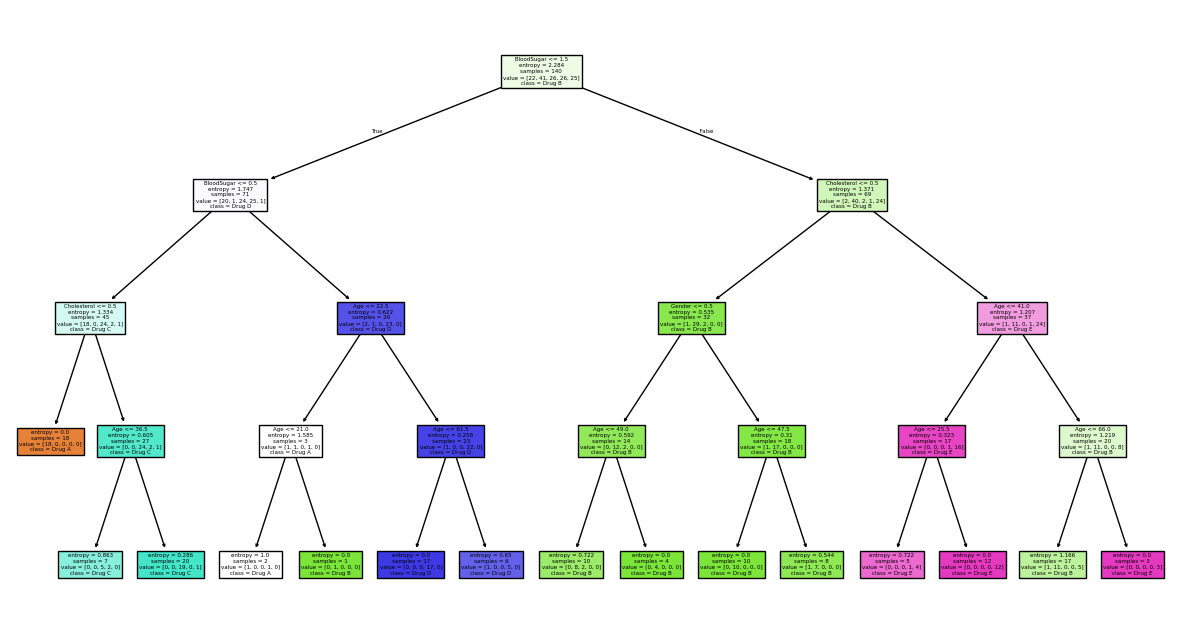

In [65]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(15,8))
plot_tree(
    drugtree,
    feature_names=['Age','Gender','Cholesterol','BloodSugar'],
    class_names=drugtree.classes_,
    filled=True
)
plt.show()